In [1]:
!pip uninstall -y massi
!pip cache purge

Found existing installation: massi 0.1.0
Uninstalling massi-0.1.0:
  Successfully uninstalled massi-0.1.0
Files removed: 6 (1.2 MB)


In [2]:
!cd .. && pip install -v . --group=dev --group=observability

Using pip 25.3 from /opt/conda/lib/python3.13/site-packages/pip (python 3.13)
Processing /home/jovyan/work
  Running command installing build dependencies
  Using pip 25.3 from /opt/conda/lib/python3.13/site-packages/pip (python 3.13)
    Obtaining dependency information for setuptools>=40.8.0 from https://files.pythonhosted.org/packages/9d/76/f789f7a86709c6b087c5a2f52f911838cad707cc613162401badc665acfe/setuptools-82.0.1-py3-none-any.whl.metadata
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 0.0/1.0 MB ? eta -:--:--
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.0/1.0 MB 9.1 MB/s  0:00:00
  Installing build dependencies ... done
  Running command Getting requirements to build wheel
  running egg_info
  writing massi.egg-info/PKG-INFO
  writing dependency_links to massi.egg-info/dependency_links.txt
  writing requirements to massi.egg-info/requires.txt
  writing top-level names to massi.egg-info/top_level.txt
  reading manifest file 'massi.egg-info/SOURCES.txt'
  writing manifest file 

In [3]:
# Setup observability
USE_OBSERVABILITY = True

if USE_OBSERVABILITY:
    import os
    from lmnr import Laminar
    
    Laminar.initialize(
        project_api_key=os.environ["LMNR_PROJECT_API_KEY"],
        base_url=f"http://{os.environ["HOST_MACHINE_URL_CORE"]}",
        http_port=int(os.environ["LMNR_PROJECT_HTTP_PORT"]),
        grpc_port=int(os.environ["LMNR_PROJECT_GRPC_PORT"]),
    )
    print("Observability is ready")

Observability is ready


In [4]:
import massi.agents.team.operators.data_explorer as de

In [5]:
import os
from massi.agents.massi import create_openai_llm, Config

In [6]:
openai_config = Config(**{"api_key": os.environ["OPENAI_API_TOKEN"], "model_name": "gpt-4.1-mini"})
openai_llm_client = create_openai_llm(openai_config)

In [7]:
explorer_request = {
    "plaintext_files": ["dwc_data/masked-doi-10.34894-72gq4c/MANIFEST.TXT"],
    "tabular_files": ["dwc_data/masked-doi-10.34894-72gq4c/budburst_occurrence.csv"],
    "instruction": "Please tell me what are all unique values in the 'class' column of the `budburst_occurrence.csv` file."
}

In [8]:
epxlorer_props = {
    "llm_client": openai_llm_client,
    "recursion_limit": 25,
    "turn_limit": 7,
}

In [9]:
data_explorer = de.DataExplorerAgent(epxlorer_props)

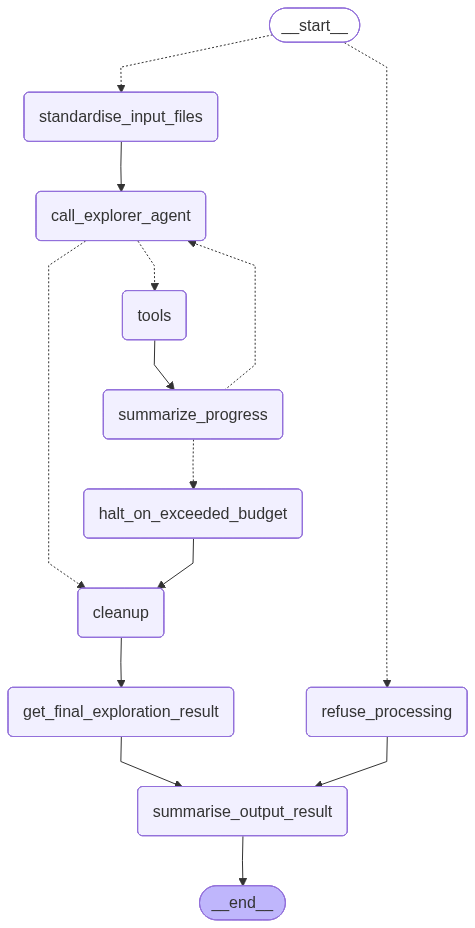

In [10]:
data_explorer.client

In [12]:
outcome = data_explorer.invoke(explorer_request)

In [13]:
outcome

{'messages': [AIMessage(content='', additional_kwargs={'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 46, 'prompt_tokens': 1906, 'total_tokens': 1952, 'completion_tokens_details': {'accepted_prediction_tokens': 0, 'audio_tokens': 0, 'reasoning_tokens': 0, 'rejected_prediction_tokens': 0}, 'prompt_tokens_details': {'audio_tokens': 0, 'cached_tokens': 0}}, 'model_provider': 'openai', 'model_name': 'gpt-4.1-mini-2025-04-14', 'system_fingerprint': 'fp_2ecf410a3e', 'id': 'chatcmpl-DW09nYKXFUPQyF3MLy1YWRaHI4jHK', 'service_tier': 'default', 'finish_reason': 'tool_calls', 'logprobs': None}, id='lc_run--019da0cf-e01c-7e62-8bca-603d2d8f021d-0', tool_calls=[{'name': 'query_dataset', 'args': {'sql_query': 'SELECT DISTINCT class FROM "/tmp/massi_4omo7xa8/tab__0_budburst_occurrence.csv" ORDER BY class LIMIT 10000'}, 'id': 'call_XszAq36cJoDgDi5g8pcuht3q', 'type': 'tool_call'}], invalid_tool_calls=[], usage_metadata={'input_tokens': 1906, 'output_tokens': 46, 'total_tokens':

In [14]:
outcome["final_output"]

{'success': True,
 'status': 'completed',
 'outcome': "Identified that the 'class' column in the budburst_occurrence.csv file contains exactly one unique value: Magnoliopsida.",
 'result_value': 'Magnoliopsida'}